(a) RANSAC line:  a=-0.7156  b=-0.6985  d=-1.5618   |[a,b]|=1.000000   inliers=57
    ground truth: normal = [-0.7071, -0.7071], d = -1.4142  (sign of [a,b,d] may be flipped)
(b) RANSAC circle: centre=(1.893, 3.018)  r=9.964  inliers=42 (of 43 remnant points)
    ground truth : centre=(2, 3)  r=10

(d) Fitting the circle FIRST on all points:
    circle: centre=(1.952, 3.054)  r=9.915  inliers=58
    line on remnant: inliers=41 of 42 remnant points


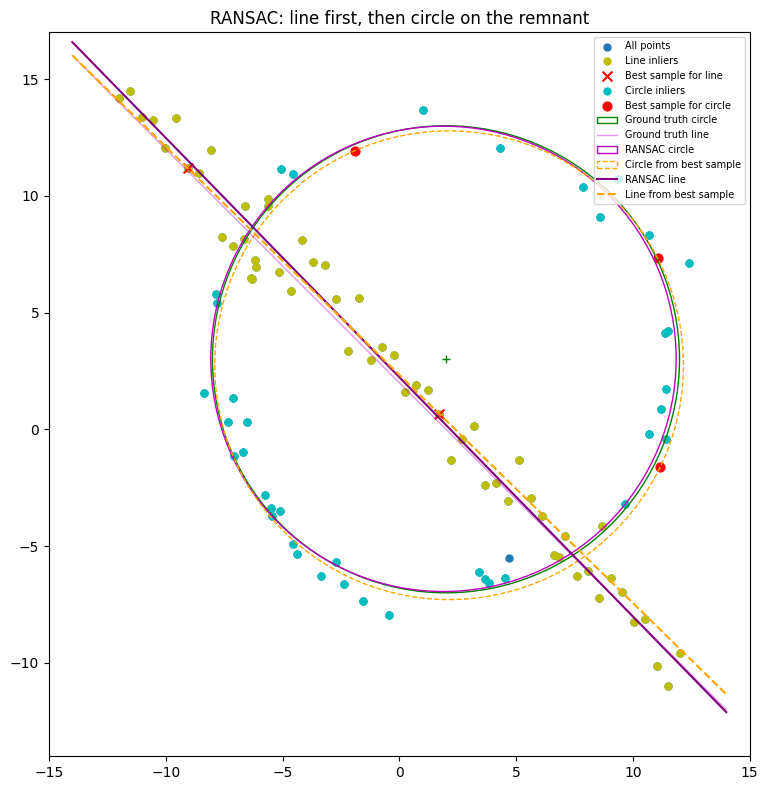

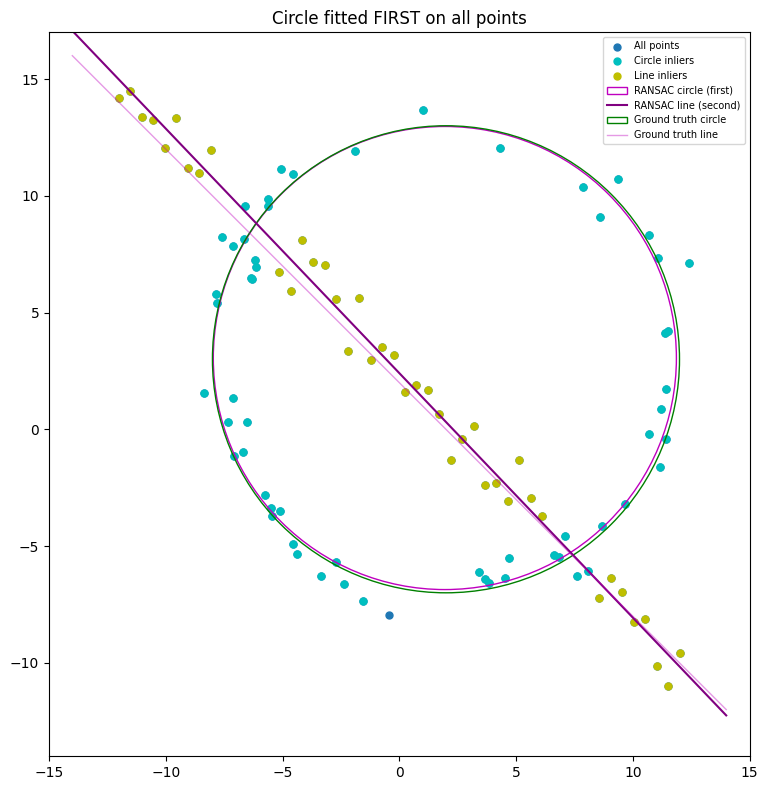

In [ ]:
# Q 2
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize


In [ ]:

np.random.seed(0)                       
N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3                     # circle centre
s = r / 16
t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)
x, y = x0_gt + (r + n) * np.cos(t), y0_gt + (r + n) * np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m * x + b + s * np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

X = np.vstack((X_circ, X_line))         # all points


def line_from_two_points(p1, p2):
    """Unit normal [a, b] and distance d of the line through p1 and p2."""
    dx, dy = p2 - p1
    nrm = np.hypot(dx, dy)
    if nrm < 1e-12:
        return None
    a, b_ = -dy / nrm, dx / nrm          
    d = a * p1[0] + b_ * p1[1]
    return np.array([a, b_, d])


def line_errors(params, pts):
    a, b_, d = params
    return np.abs(a * pts[:, 0] + b_ * pts[:, 1] - d)


def refine_line(pts, init):
    cost = lambda p: np.sum((p[0] * pts[:, 0] + p[1] * pts[:, 1] - p[2]) ** 2)
    cons = {'type': 'eq', 'fun': lambda p: p[0] ** 2 + p[1] ** 2 - 1}
    res = minimize(cost, init, constraints=cons, method='SLSQP')
    return res.x


def ransac_line(pts, thresh, min_inliers, n_iter=500):
    best = dict(count=-1, params=None, inliers=None, sample=None)
    rng = np.random.default_rng()
    for _ in range(n_iter):
        idx = rng.choice(len(pts), 2, replace=False)
        model = line_from_two_points(pts[idx[0]], pts[idx[1]])
        if model is None:
            continue
        inl = line_errors(model, pts) < thresh
        if inl.sum() > best['count']:
            best.update(count=int(inl.sum()), params=model, inliers=inl, sample=pts[idx])
    if best['count'] < min_inliers:
        raise RuntimeError('Line: consensus too small')
    best['refined'] = refine_line(pts[best['inliers']], best['params'])
    return best


def circle_from_three_points(p1, p2, p3):
    A = np.array([[p2[0] - p1[0], p2[1] - p1[1]],
                  [p3[0] - p1[0], p3[1] - p1[1]]]) * 2.0
    rhs = np.array([p2 @ p2 - p1 @ p1, p3 @ p3 - p1 @ p1])
    if abs(np.linalg.det(A)) < 1e-9:
        return None
    c = np.linalg.solve(A, rhs)
    return np.array([c[0], c[1], np.linalg.norm(p1 - c)])


def circle_errors(params, pts):
    cx, cy, rad = params
    return np.abs(np.hypot(pts[:, 0] - cx, pts[:, 1] - cy) - rad)


def refine_circle(pts, init):
    cost = lambda p: np.sum((np.hypot(pts[:, 0] - p[0], pts[:, 1] - p[1]) - p[2]) ** 2)
    return minimize(cost, init, method='BFGS').x


def ransac_circle(pts, thresh, min_inliers, n_iter=1000):
    best = dict(count=-1, params=None, inliers=None, sample=None)
    rng = np.random.default_rng()
    for _ in range(n_iter):
        idx = rng.choice(len(pts), 3, replace=False)
        model = circle_from_three_points(*pts[idx])
        if model is None or model[2] > MAX_R:       
            continue
        inl = circle_errors(model, pts) < thresh
        if inl.sum() > best['count']:
            best.update(count=int(inl.sum()), params=model, inliers=inl, sample=pts[idx])
    if best['count'] < min_inliers:
        raise RuntimeError('Circle: consensus too small')
    best['refined'] = refine_circle(pts[best['inliers']], best['params'])
    return best


MAX_R = 50   
LINE_THRESH, LINE_MIN_INL = 1.5, 30
CIRC_THRESH, CIRC_MIN_INL = 1.2, 25


def plot_result(X, line_res, circ_res, remnant, title, fname):
    fig, ax = plt.subplots(1, 1, figsize=(8, 8))
    ax.scatter(X[:, 0], X[:, 1], c='tab:blue', s=25, label='All points')

    if line_res is not None:
        li = line_res['inliers']
        ax.scatter(X[li, 0], X[li, 1], c='y', s=25, label='Line inliers')
        ax.scatter(line_res['sample'][:, 0], line_res['sample'][:, 1],
                   c='r', marker='x', s=50, label='Best sample for line')
   
    if circ_res is not None:
        ci = circ_res['inliers']
        ax.scatter(remnant[ci, 0], remnant[ci, 1], c='c', s=25, label='Circle inliers')
        ax.scatter(circ_res['sample'][:, 0], circ_res['sample'][:, 1],
                   c='r', s=40, label='Best sample for circle')

    
    ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle'))
    ax.plot(x0_gt, y0_gt, '+', color='g')
    xl = np.array([-14, 14])
    ax.plot(xl, m * xl + b, color='m', alpha=0.4, lw=1, label='Ground truth line')

    
    if circ_res is not None:
        cx, cy, rad = circ_res['refined']
        ax.add_patch(plt.Circle((cx, cy), rad, color='m', fill=False, label='RANSAC circle'))
        sx, sy, sr = circ_res['params']         
        ax.add_patch(plt.Circle((sx, sy), sr, color='orange', fill=False, ls='--',
                                label='Circle from best sample'))
    if line_res is not None:
        a, b_, d = line_res['refined']
        ys = (d - a * xl) / b_ if abs(b_) > 1e-9 else None
        ax.plot(xl, ys, color='purple', label='RANSAC line')
        a0, b0, d0 = line_res['params']          
        ys0 = (d0 - a0 * xl) / b0
        ax.plot(xl, ys0, color='orange', ls='--', label='Line from best sample')

    ax.set_aspect('equal')
    ax.set_xlim(-15, 15); ax.set_ylim(-14, 17)
    ax.set_title(title)
    ax.legend(fontsize=7, loc='upper right')
    plt.tight_layout()
    plt.savefig(fname, dpi=150)



In [ ]:

def main():
    line_res = ransac_line(X, LINE_THRESH, LINE_MIN_INL)
    a, b_, d = line_res['refined']
    print('(a) RANSAC line:  a=%.4f  b=%.4f  d=%.4f   |[a,b]|=%.6f   inliers=%d'
          % (a, b_, d, np.hypot(a, b_), line_res['count']))
    print('    ground truth: normal = [%.4f, %.4f], d = %.4f'
          % (m / np.hypot(m, 1), -1 / np.hypot(m, 1), -b / np.hypot(m, 1)) +
          '  (sign of [a,b,d] may be flipped)')

    remnant = X[~line_res['inliers']]
    circ_res = ransac_circle(remnant, CIRC_THRESH, CIRC_MIN_INL)
    cx, cy, rad = circ_res['refined']
    print('(b) RANSAC circle: centre=(%.3f, %.3f)  r=%.3f  inliers=%d (of %d remnant points)'
          % (cx, cy, rad, circ_res['count'], len(remnant)))
    print('    ground truth : centre=(%d, %d)  r=%d' % (x0_gt, y0_gt, r))

    plot_result(X, line_res, circ_res, remnant,
                'RANSAC: line first, then circle on the remnant', 'q2_line_then_circle.png')

    print('\n(d) Fitting the circle FIRST on all points:')
    circ_first = ransac_circle(X, CIRC_THRESH, 20)
    cx2, cy2, r2 = circ_first['refined']
    print('    circle: centre=(%.3f, %.3f)  r=%.3f  inliers=%d' % (cx2, cy2, r2, circ_first['count']))
    remnant2 = X[~circ_first['inliers']]
    line_second = ransac_line(remnant2, LINE_THRESH, 15)
    print('    line on remnant: inliers=%d of %d remnant points' % (line_second['count'], len(remnant2)))
    # plot (line inliers indexed w.r.t. remnant2)
    fig, ax = plt.subplots(1, 1, figsize=(8, 8))
    ax.scatter(X[:, 0], X[:, 1], s=25, label='All points')
    ax.scatter(X[circ_first['inliers'], 0], X[circ_first['inliers'], 1], c='c', s=25, label='Circle inliers')
    ax.scatter(remnant2[line_second['inliers'], 0], remnant2[line_second['inliers'], 1],
               c='y', s=25, label='Line inliers')
    ax.add_patch(plt.Circle((cx2, cy2), r2, color='m', fill=False, label='RANSAC circle (first)'))
    a2, b2, d2 = line_second['refined']
    xl = np.array([-14, 14]); ax.plot(xl, (d2 - a2 * xl) / b2, color='purple', label='RANSAC line (second)')
    ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle'))
    ax.plot(xl, m * xl + b, color='m', alpha=0.4, lw=1, label='Ground truth line')
    ax.set_aspect('equal'); ax.set_xlim(-15, 15); ax.set_ylim(-14, 17)
    ax.set_title('Circle fitted FIRST on all points'); ax.legend(fontsize=7)
    plt.tight_layout(); plt.savefig('q2_circle_first.png', dpi=150)
    plt.show()


if __name__ == '__main__':
    main()